In [3]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from jaxopt import AndersonAcceleration
import pickle
import optax
import seaborn as sns
from scipy.stats import t as student_t
from tqdm import trange
from sklearn.cluster import KMeans
from scipy.optimize import linear_sum_assignment
# Model parameters
m = 2  # Number of mitral neurons (glomeruli)


n_r = 1.850
n_g = 1.868
n_b = 0.642
n_y = 1.562

# OSN input (must match the condition used for theta_opt / Hessian cells below)
x = jnp.array([0.5, 0.5])

In [4]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

In [5]:

def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    # Build 2x2 matrices so all elements are same type (avoids JAX shape error)
    zero = jnp.asarray(0.0)
    wr = jnp.asarray(theta[10])
    wy = jnp.asarray(theta[11])
    W_g_r = jnp.stack([jnp.stack([zero, wr]), jnp.stack([wr, zero])])
    W_g_y = jnp.stack([jnp.stack([zero, wy]), jnp.stack([wy, zero])])
    n_g_val = theta[12]
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val


# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Pass n_g_val as explicit arg so JAX can differentiate w.r.t. it (closed-over values break custom_vjp)
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_g_val):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g_val)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_g_val)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

In [6]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_214_2_points_final.pkl'

with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (214, 13)
Number of samples: 214
Number of parameters per sample: 13


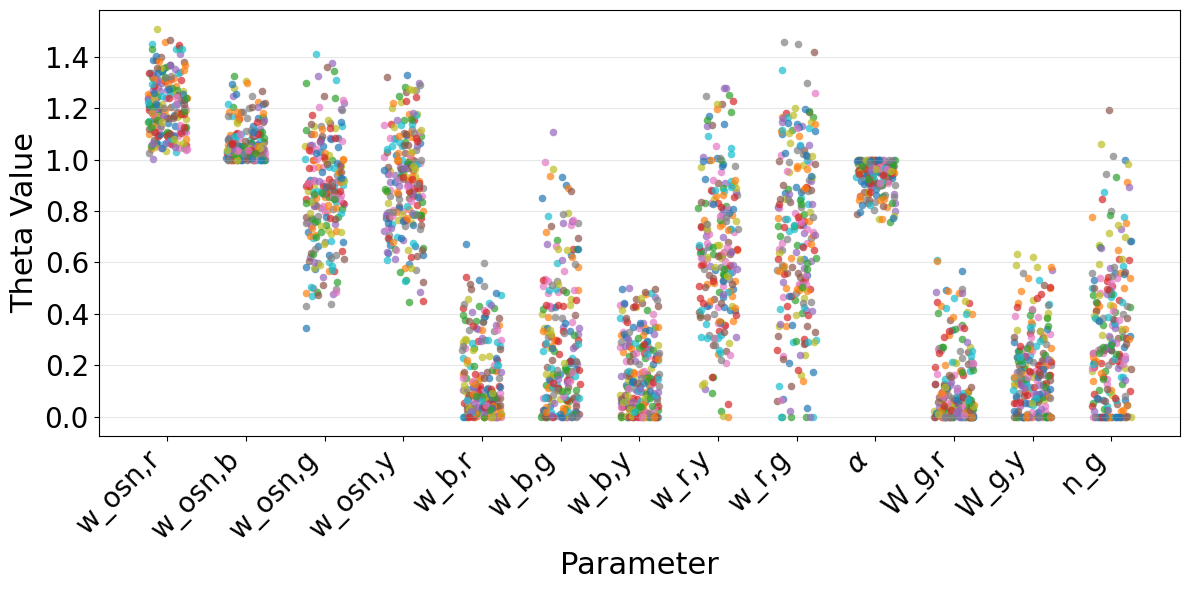

In [64]:
param_labels = [
    'w_osn,r', 'w_osn,b', 'w_osn,g', 'w_osn,y',
    'w_b,r', 'w_b,g', 'w_b,y',
    'w_r,y', 'w_r,g', r'$\alpha$', 'W_g,r', 'W_g,y',
    'n_g',
]

theta_opt.shape
no_samples = theta_opt.shape[0]
n_params = theta_opt.shape[1]
param_names = param_labels[:n_params]

x_params = np.arange(n_params)
plt.figure(figsize=(12, 6))
for i in range(no_samples):
    plt.scatter(
        x_params + np.random.uniform(-0.25, 0.25, n_params),
        theta_opt[i, :],
        alpha=0.7,
        s=30,
        linewidths=0,
        label=f'Sample {i + 1}',
    )
plt.xticks(x_params, param_names, rotation=45, ha='right')
plt.xlabel('Parameter', fontsize=22)
plt.ylabel('Theta Value', fontsize=22)
plt.xticks(rotation=45, ha='right')
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

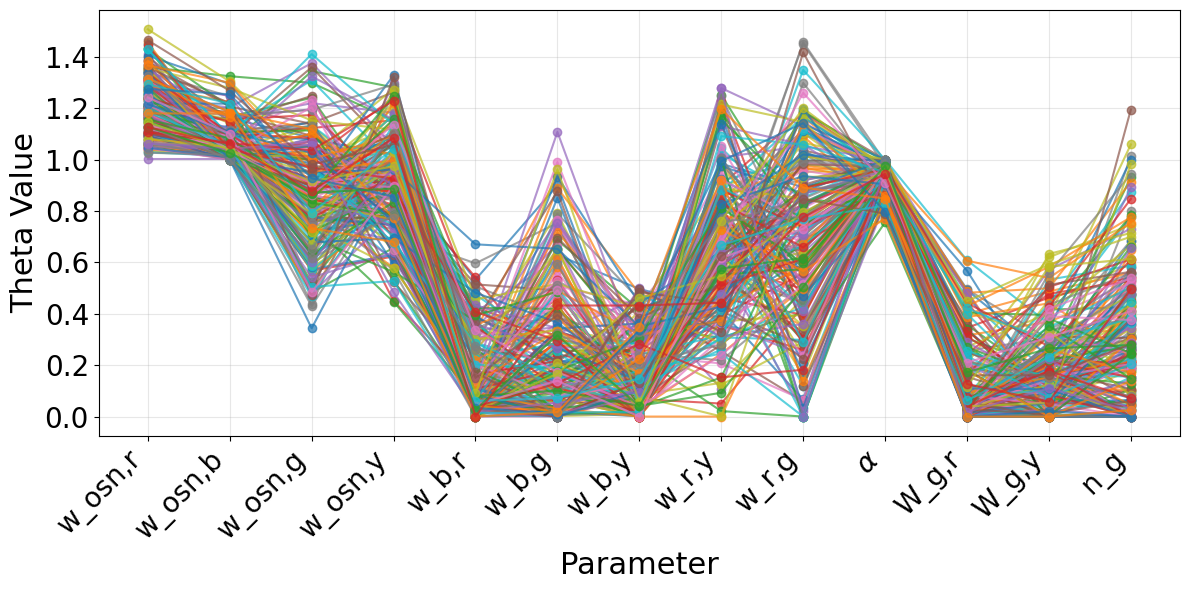

In [66]:
plt.figure(figsize=(12, 6))
for i in range(no_samples):
    plt.plot(
        x_params,
        theta_opt[i, :],
        'o-',
        alpha=0.7,
        lw=1.5,
        ms=6,
        label=f'Sample {i + 1}',
    )
plt.xticks(x_params, param_names, rotation=45, ha='right')
plt.xlabel('Parameter', fontsize=22)
plt.ylabel('Theta Value', fontsize=22)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 12. Stability (2 op)


In [8]:
# Define the dynamics function F(s, theta, x, m) with different n values
# State vector s = [r, g, y]
def F(s, theta, x, m, n_r=1.850, n_b=0.642, n_y=1.562):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)

    # Compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x, n=n_b)

    # Compute new r from current g
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)

    # Compute new g from current r
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r, n=n_g_val)

    # Compute new y from g_new and r_new
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new, n=n_y)

    # Return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime

# Compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_y):
    # Create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m, n_r, n_b, n_y)

    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J

# Compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0, n_r=2.333, n_b=0.9, n_y=1.562):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_y)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # Check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts,
        'imag_parts': np.imag(eigenvalues_np)
    }



In [9]:
# Use a subset of samples for faster analysis
n_samples_to_analyze = 214 #theta_opt.shape[0]
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"\nUsing {n_samples_to_analyze} samples for analysis")


Using 214 samples for analysis



--- Stability at in_1.0_out_0.5 ---


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


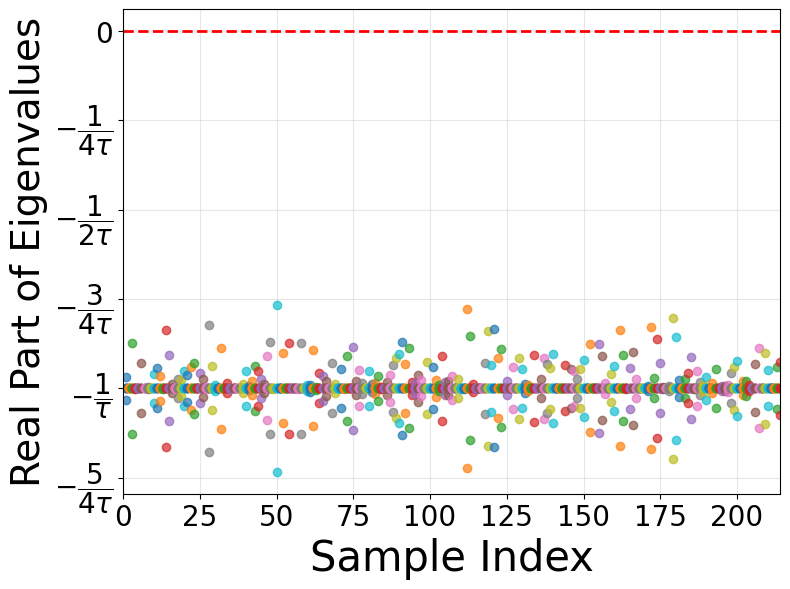


STABILITY SUMMARY

Stable samples: 214/214 (100.0%)


In [10]:
# Analyze stability 
# Operating point: in=1.0, out=0.5

from fractions import Fraction
from matplotlib.ticker import FixedLocator


def y_tick_frac_label(k_quarters):
    """Label for tick at -k_quarters/(4*tau): minus sign outside stacked fraction."""
    if k_quarters == 0:
        return '0'
    f = Fraction(k_quarters, 4)
    num, den = f.numerator, f.denominator
    if den == 1:
        return rf'$-\dfrac{{{num}}}{{\tau}}$'
    return rf'$-\dfrac{{{num}}}{{{den}\tau}}$'


def apply_stability_yaxis(ax, stability_results, tau=1.0):
    """Y limits and quarter-τ tick labels (same as TTFinal_report_c_stability)."""
    all_real_parts = np.concatenate([r['real_parts'] for r in stability_results])
    y_min_data = np.min(all_real_parts)
    y_pad = max(0.02, 0.05 * abs(y_min_data))
    y_top = y_pad
    y_bottom = y_min_data - y_pad
    k_max = int(np.ceil(-y_bottom * 4 * tau))
    y_tick_positions = [-k / (4 * tau) for k in range(0, k_max + 1)]
    y_tick_labels = [y_tick_frac_label(k) for k in range(0, k_max + 1)]
    ax.set_ylim(y_bottom, y_top)
    ax.yaxis.set_major_locator(FixedLocator(y_tick_positions))
    ax.set_yticklabels(y_tick_labels)


stability_results_all = {}

# Choose operating points to test
ops = {
    "in_1.0_out_0.5": jnp.ones(m) * 1.0,
}


for op_name, x_op in ops.items():
    print(f"\n--- Stability at {op_name} ---")

    stability_results = []
    max_real_parts = []
    min_real_parts = []
    all_eigenvalues = []

    for i in range(n_samples_to_analyze):
        theta_star = theta_subset[i, :]

        try:
            # Fixed point outputs at this operating point
            r_star, g_star, b_star, y_star = mitral_output(theta_star, x_op, m, n_r, n_b, n_y)

            # Construct state vector s* = [r, g, y]
            s_star = jnp.concatenate([r_star, g_star, y_star])

            # Verify it's a fixed point
            s_prime = F(s_star, theta_star, x_op, m, n_r, n_b, n_y)
            s_error = jnp.linalg.norm(s_prime - s_star)
            if s_error > 1e-3:
                print(f"  Sample {i+1}: Warning - fixed point error = {s_error:.2e}")

            # Compute stability (n_g is taken from theta[12] via unpack_theta)
            result = compute_stability(F, s_star, theta_star, x_op, m, tau=1.0, n_r=n_r, n_b=n_b, n_y=n_y)
            stability_results.append(result)

            max_real_parts.append(np.max(result['real_parts']))
            min_real_parts.append(np.min(result['real_parts']))
            all_eigenvalues.append(result['eigenvalues'])

        except Exception as e:
            print(f"  Sample {i+1}: Error - {e}")
            continue

    stability_results_all[op_name] = {
        "stability_results": stability_results,
        "max_real_parts": max_real_parts,
        "min_real_parts": min_real_parts,
        "all_eigenvalues": all_eigenvalues,
    }

    # visualise stability results
    fig, ax1 = plt.subplots(1, 1, figsize=(8, 6))

    actual_no_samples = len(stability_results)
    for i in range(actual_no_samples):
        real_parts = stability_results[i]['real_parts']
        ax1.plot([i + 1] * len(real_parts), real_parts, 'o', alpha=0.7, label=f'Sample {i + 1}' if i < 5 else '')

    ax1.axhline(y=0, color='r', linestyle='--', linewidth=2, label='Stability threshold')
    ax1.set_xlabel('Sample Index', fontsize=30)
    ax1.set_ylabel('Real Part of Eigenvalues', fontsize=28)
    ax1.set_xlim(0, max(actual_no_samples, 1))
    if actual_no_samples > 0:
        apply_stability_yaxis(ax1, stability_results, tau=1.0)
    ax1.grid(True, alpha=0.3)

    stable_count = sum(1 for r in stability_results if r['is_stable'])

    plt.tight_layout()
    plt.tick_params(axis='both', direction='out')
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=20)
    plt.tight_layout()
    plt.savefig(f'Figures_final/stability_two_op.eps')
    plt.show()

    # print summary
    print("\n" + "=" * 70)
    print("STABILITY SUMMARY")
    print("=" * 70)
    if actual_no_samples > 0:
        print(f"\nStable samples: {stable_count}/{actual_no_samples} ({100 * stable_count / actual_no_samples:.1f}%)")
    else:
        print("\nNo valid samples to summarise.")



--- Stability at in_0.5_out_0.2 (input x=0.5, target y=0.2) ---


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


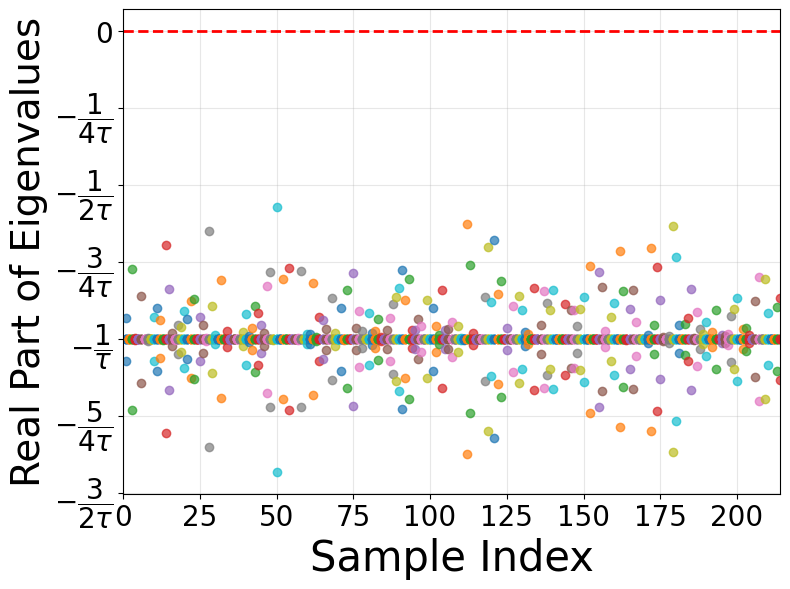


STABILITY SUMMARY (input x=0.5, target y=0.2)

Stable samples: 214/214 (100.0%)


In [11]:
# Stability at operating point: input x=0.5, target mitral output y=0.2
# (two-point theta_opt: at x=0.5 only y is fit to 0.2; at x=1.0 r,g,b,y → 0.5)

x_in = 0.5
y_target = 0.2
op_name = "in_0.5_out_0.2"
x_op = jnp.ones(m) * x_in

print(f"\n--- Stability at {op_name} (input x={x_in}, target y={y_target}) ---")

stability_results = []
max_real_parts = []
min_real_parts = []
all_eigenvalues = []

for i in range(n_samples_to_analyze):
    theta_star = theta_subset[i, :]

    try:
        # Fixed point at OSN input x=0.5 (mitral y should be ≈ 0.2 from optimisation)
        r_star, g_star, b_star, y_star = mitral_output(theta_star, x_op, m, n_r, n_b, n_y)

        y_err = float(jnp.max(jnp.abs(y_star - y_target)))
        if y_err > 0.05:
            print(f"  Sample {i+1}: Warning - y = {np.array(y_star)}, max |y - {y_target}| = {y_err:.4f}")

        s_star = jnp.concatenate([r_star, g_star, y_star])

        s_prime = F(s_star, theta_star, x_op, m, n_r, n_b, n_y)
        s_error = jnp.linalg.norm(s_prime - s_star)
        if s_error > 1e-3:
            print(f"  Sample {i+1}: Warning - fixed point error = {s_error:.2e}")

        result = compute_stability(F, s_star, theta_star, x_op, m, tau=1.0, n_r=n_r, n_b=n_b, n_y=n_y)
        stability_results.append(result)

        max_real_parts.append(np.max(result['real_parts']))
        min_real_parts.append(np.min(result['real_parts']))
        all_eigenvalues.append(result['eigenvalues'])

    except Exception as e:
        print(f"  Sample {i+1}: Error - {e}")
        continue

stability_results_all[op_name] = {
    "stability_results": stability_results,
    "max_real_parts": max_real_parts,
    "min_real_parts": min_real_parts,
    "all_eigenvalues": all_eigenvalues,
}

# visualise stability results (same formatting as cell above)
fig, ax1 = plt.subplots(1, 1, figsize=(8, 6))

actual_no_samples = len(stability_results)
for i in range(actual_no_samples):
    real_parts = stability_results[i]['real_parts']
    ax1.plot([i + 1] * len(real_parts), real_parts, 'o', alpha=0.7, label=f'Sample {i + 1}' if i < 5 else '')

ax1.axhline(y=0, color='r', linestyle='--', linewidth=2, label='Stability threshold')
ax1.set_xlabel('Sample Index', fontsize=30)
ax1.set_ylabel('Real Part of Eigenvalues', fontsize=28)
ax1.set_xlim(0, max(actual_no_samples, 1))
if actual_no_samples > 0:
    apply_stability_yaxis(ax1, stability_results, tau=1.0)
ax1.grid(True, alpha=0.3)

stable_count = sum(1 for r in stability_results if r['is_stable'])

plt.tight_layout()
plt.tick_params(axis='both', direction='out')
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.tight_layout()
plt.savefig('Figures_final/stability_in_0.5_out_0.2.eps')
plt.show()

# print summary
print("\n" + "=" * 70)
print(f"STABILITY SUMMARY (input x={x_in}, target y={y_target})")
print("=" * 70)
if actual_no_samples > 0:
    print(f"\nStable samples: {stable_count}/{actual_no_samples} ({100 * stable_count / actual_no_samples:.1f}%)")
else:
    print("\nNo valid samples to summarise.")

All stable, therefore can just use theta_opt

## 13. Hessian (2 op)


Processing 214 samples...
  Sample 1/214...


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


  Sample 101/214...
  Sample 201/214...
Completed processing 214 samples


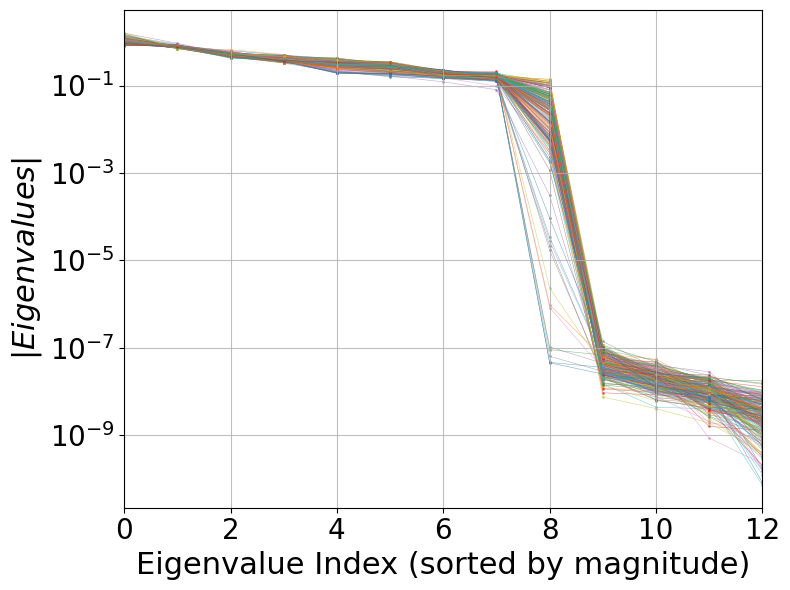

In [12]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_y)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-5

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(8, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (one colour per sample)
x_idx = np.arange(n_params)
for i in range(n_samples):
    ax.semilogy(x_idx, all_eigenvalues[i, :], 'o-', ms=1, lw=0.4, alpha=0.6, zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=22)
ax.set_ylabel('$|Eigenvalues|$', fontsize=22)
ax.set_xlim(0, n_params-1)
ax.tick_params(axis='both', labelsize=20, direction='out')
ax.grid(True, alpha=0.8)
plt.tight_layout()
plt.savefig('Figures_final/hessian_eigenvalues_two_op.eps')
plt.show()

In [13]:

threshold = 1e-6  # Threshold for near-zero eigenvalues

def get_subspace2_eigenvectors(sample_idx, all_eigenvalues, all_eigenvectors, threshold=1e-5):

    eigenvalues = all_eigenvalues[sample_idx, :]
    eigenvectors = all_eigenvectors[sample_idx, :, :]  # Shape: (n_params, n_params)

    # Find indices where eigenvalues < threshold
    near_zero_mask = eigenvalues < threshold
    n_near_zero = np.sum(near_zero_mask)

    # Extract corresponding eigenvectors (each column is an eigenvector)
    eigenvectors_subspace2 = eigenvectors[:, near_zero_mask].T  # Shape: (n_near_zero, n_params)

    return eigenvectors_subspace2

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


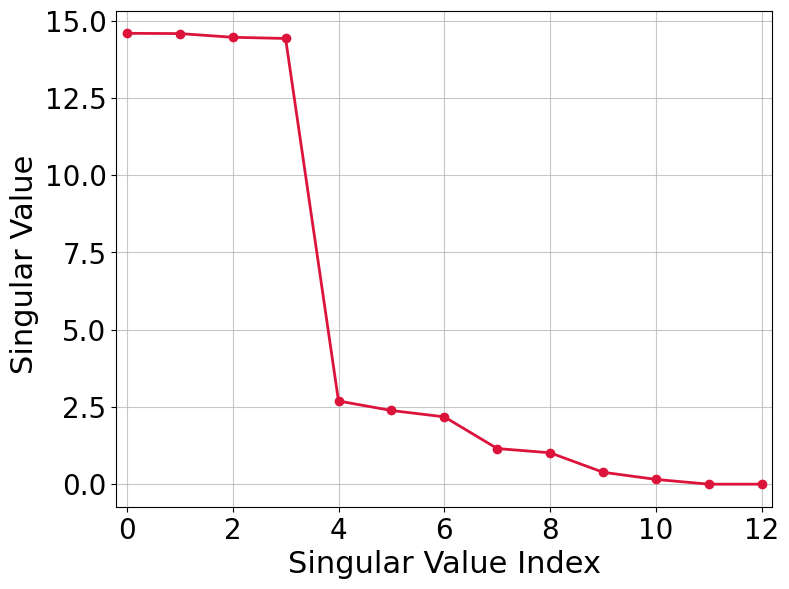

In [14]:

# Concatenate all near-zero eigenvectors from all samples
all_eigenvectors_subspace2 = []
for i in range(n_samples):
    vecs = get_subspace2_eigenvectors(i, all_eigenvalues, all_eigenvectors, threshold=threshold)
    all_eigenvectors_subspace2.append(vecs)
# Stack all (variable-sized, so use vstack)
eigenvectors_concat = np.vstack(all_eigenvectors_subspace2)  # Shape: (total_vectors, n_params)

# Perform SVD on concatenated eigenvectors
U, S, Vt = np.linalg.svd(eigenvectors_concat, full_matrices=False)

# Plot singular values vs index
plt.figure(figsize=(8, 6))
plt.plot(np.arange(0, len(S)), S, 'o-', color='crimson', lw=2, ms=6)
plt.xlabel('Singular Value Index', fontsize=22)
plt.ylabel('Singular Value ', fontsize=22)
plt.xlim(-0.2, len(S)-1+0.2)
plt.grid(True, alpha=0.7)
plt.tick_params(axis='both', labelsize=20)
plt.tight_layout()
plt.savefig('Figures_final/svd_singular_values_two_op.eps')
plt.show()

## 14. Find sparse rotation (2 op)


In [15]:
def sparse_rotation_vectorized(U, keys, learning_rate=0.01, n_iterations=10000):
    """Find sparse rotations for many random Q initialisations (JIT + vmap)."""
    k = U.shape[1]

    def loss(qtilde):
        q, _ = jnp.linalg.qr(qtilde)
        return jnp.mean(jnp.abs(U @ q))

    def optimize_single(key):
        key, subkey = jax.random.split(key)
        qtilde = jax.random.normal(subkey, (k, k))
        optimizer = optax.adam(learning_rate=learning_rate, eps=1e-4)
        opt_state = optimizer.init(qtilde)
        loss_value_and_grad = jax.value_and_grad(loss)

        def step(carry, _):
            qtilde, opt_state = carry
            loss_value, grads = loss_value_and_grad(qtilde)
            updates, opt_state = optimizer.update(grads, opt_state)
            qtilde = optax.apply_updates(qtilde, updates)
            return (qtilde, opt_state), loss_value

        (qtilde_final, _), loss_history = jax.lax.scan(
            step, (qtilde, opt_state), jnp.arange(n_iterations)
        )
        q_opt, _ = jnp.linalg.qr(qtilde_final)
        return U @ q_opt, loss_history[-1]

    return jax.jit(jax.vmap(optimize_single))(keys)


def sparse_rotation(U, key=0, learning_rate=0.01, n_iterations=10000, verbose=False):
    """Single-initialisation wrapper around sparse_rotation_vectorized."""
    key = jax.random.PRNGKey(key) if isinstance(key, int) else key
    U_sparse, loss = sparse_rotation_vectorized(
        U, jnp.array([key]),
        learning_rate=learning_rate,
        n_iterations=n_iterations,
    )
    if verbose:
        print(f"Final loss: {float(loss[0]):.6f}")
    return np.asarray(U_sparse[0]), float(loss[0])

## 15. Many Q tilde initialisations (2 op)




In [16]:
# Vectorized version of sparse_rotation for parallelization
def sparse_rotation_vectorized(U, keys, use_scheduler=True, scheduler_type='plateau', n_iterations=10000):

    batch_size = keys.shape[0]
    k = U.shape[1]
    n = U.shape[0]
    
    def loss(qtilde):
        """Loss function: mean of absolute values of rotated u"""
        q, _ = jnp.linalg.qr(qtilde)
        u_rotated = U @ q
        return jnp.mean(jnp.abs(u_rotated))
    
    def optimize_single(key):
        """Optimize for a single initialization"""
        key, subkey = jax.random.split(key)
        qtilde = jax.random.normal(subkey, (k, k))
        
        # Set up optimizer
        if use_scheduler:
            if scheduler_type == 'cosine':
                schedule = optax.cosine_decay_schedule(
                    init_value=0.01,
                    decay_steps=n_iterations,
                    alpha=0.1
                )
                optimizer = optax.chain(
                    optax.scale_by_adam(eps=1e-4),
                    optax.scale_by_schedule(schedule)
                )
            elif scheduler_type == 'step':
                schedule = optax.piecewise_constant_schedule(
                    init_value=0.01,
                    boundaries_and_scales={5000: 0.5, 8000: 0.5}
                )
                optimizer = optax.chain(
                    optax.scale_by_adam(eps=1e-4),
                    optax.scale_by_schedule(schedule)
                )
            else:  # 'plateau' or default
                # For plateau, use fixed LR of 0.01
                # The original plateau scheduler keeps LR at 0.01 for most iterations
                # (reduces only when loss plateaus, typically after 3000+ iterations)
                # Using fixed 0.01 should give similar results since most optimization
                # happens at this LR anyway
                optimizer = optax.adam(learning_rate=0.01, eps=1e-4)
        else:
            optimizer = optax.adam(learning_rate=0.01, eps=1e-4)
        
        opt_state = optimizer.init(qtilde)
        loss_value_and_grad = jax.value_and_grad(loss)
        
        # Optimization loop - use scan for efficiency
        def step(carry, i):
            qtilde, opt_state = carry
            loss_value, grads = loss_value_and_grad(qtilde)
            updates, opt_state = optimizer.update(grads, opt_state)
            qtilde = optax.apply_updates(qtilde, updates)
            return (qtilde, opt_state), loss_value
        
        (qtilde_final, _), loss_history = jax.lax.scan(
            step, (qtilde, opt_state), jnp.arange(n_iterations)
        )
        
        # Get final Q
        q_opt, _ = jnp.linalg.qr(qtilde_final)
        U_sparse = U @ q_opt
        
        return U_sparse, loss_history[-1]
    
    # Vectorize over keys using vmap and JIT compile for speed
    optimize_batch = jax.jit(jax.vmap(optimize_single))
    
    # Process all keys in parallel (JIT compilation happens on first call)
    U_sparse_batch, loss_values = optimize_batch(keys)
    
    return U_sparse_batch, loss_values

In [17]:
# PARALLELIZED VERSION - Use this instead
n_key = 1000
batch_size = 100  # Process in batches to manage memory

n, k = Vt[:4].T.shape

# Configuration
config = {'use_scheduler': True, 'scheduler_type': 'plateau', 'label': 'Plateau Scheduler'}

# Generate all random keys upfront
print(f"Generating {n_key} random keys...")
keys = jax.random.split(jax.random.PRNGKey(0), n_key)

# Process in batches for memory efficiency
print(f"Processing {n_key} initializations in batches of {batch_size}...")
U_sparse_all = []
loss_values_all = []

for batch_start in trange(0, n_key, batch_size):
    batch_end = min(batch_start + batch_size, n_key)
    batch_keys = keys[batch_start:batch_end]
    
    # Process batch in parallel using JAX vmap
    U_sparse_batch, loss_batch = sparse_rotation_vectorized(
        Vt[:4].T,
        batch_keys,
        use_scheduler=config['use_scheduler'],
        scheduler_type=config['scheduler_type'] if config['use_scheduler'] else None,
        n_iterations=10000
    )
    
    U_sparse_all.append(np.array(U_sparse_batch))
    loss_values_all.append(np.array(loss_batch))

# Concatenate results
U_sparse_coll = np.concatenate(U_sparse_all, axis=0)
loss_value_coll = np.concatenate(loss_values_all, axis=0)

print(f"\nCompleted! Processed {n_key} initializations.")
print(f"Loss range: [{loss_value_coll.min():.6f}, {loss_value_coll.max():.6f}]")
print(f"Mean loss: {loss_value_coll.mean():.6f}")

np.savez_compressed('U_sparse_save.npz', U_sparse_coll=U_sparse_coll, loss_value_coll=loss_value_coll)

Generating 1000 random keys...
Processing 1000 initializations in batches of 100...


100%|██████████| 10/10 [00:13<00:00,  1.32s/it]


Completed! Processed 1000 initializations.
Loss range: [0.130761, 0.162482]
Mean loss: 0.132788


In [18]:
U_sparse_save = np.load('U_sparse_save.npz')['U_sparse_coll']
loss_value_coll = np.load('U_sparse_save.npz')['loss_value_coll']
U_sparse_save.shape
#loss_value_coll.shape

(1000, 13, 4)

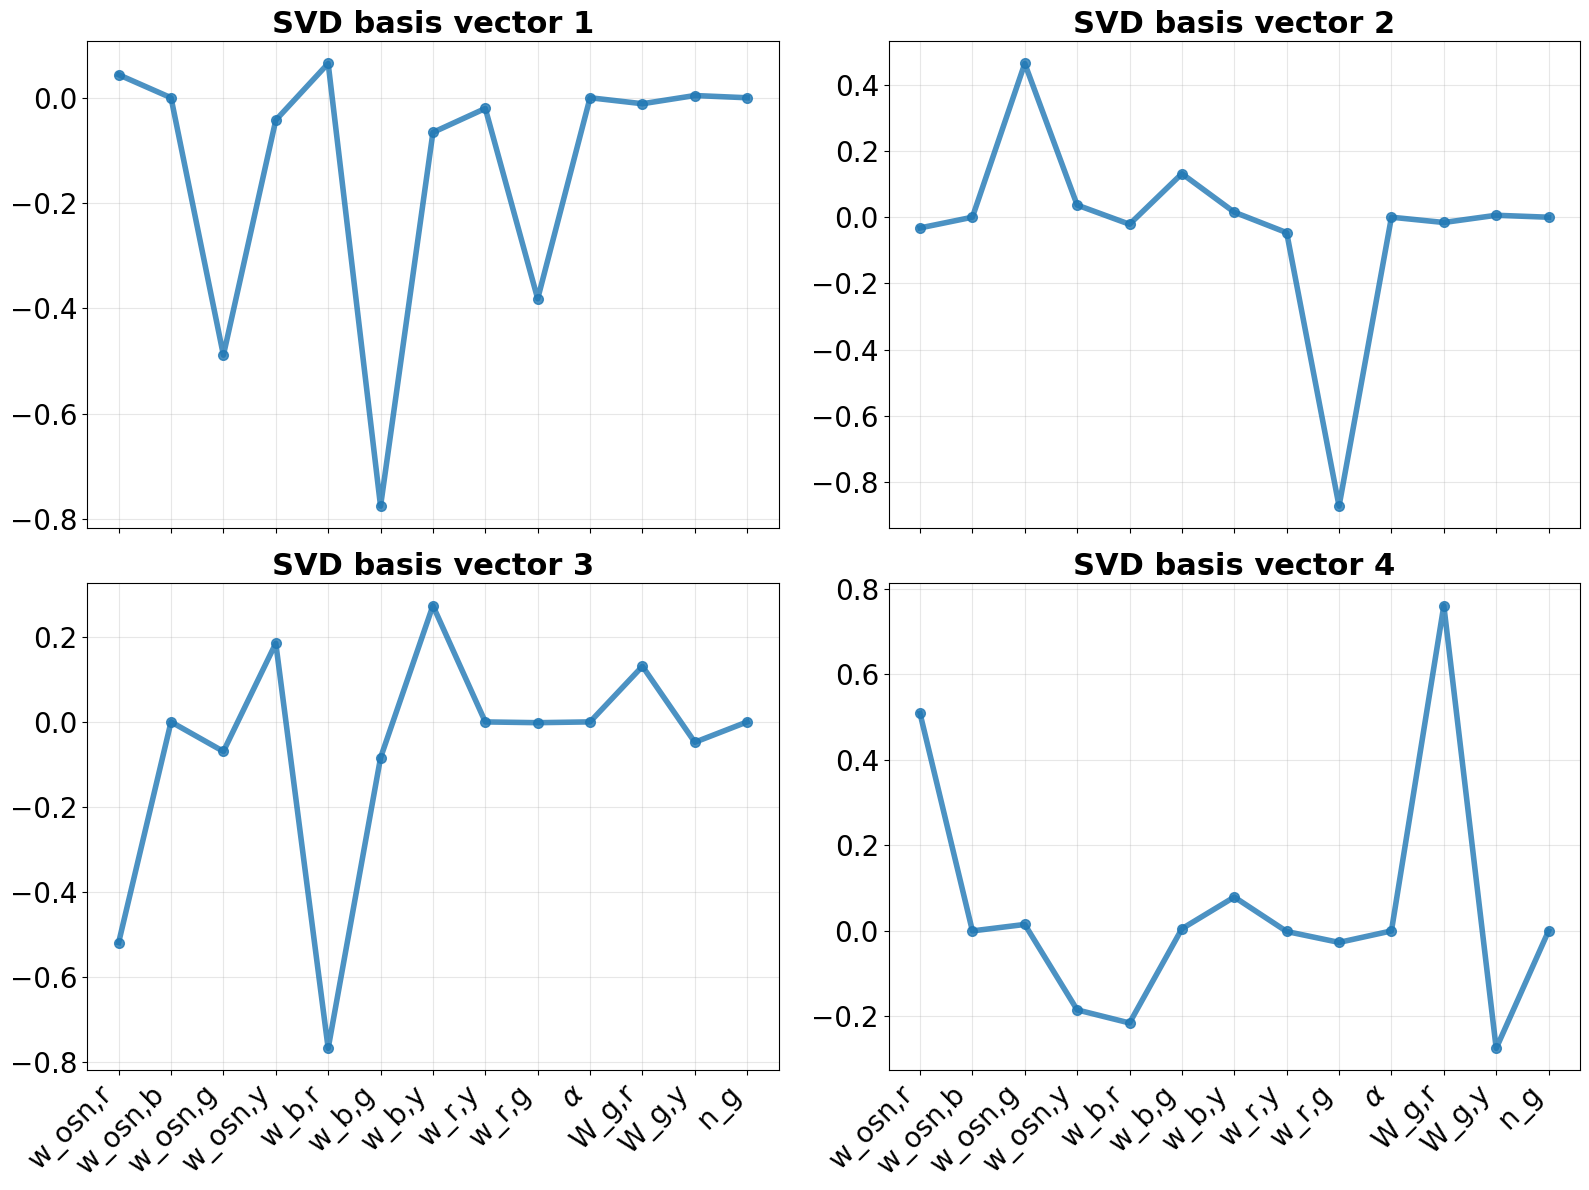

In [41]:
# SVD basis (before sparse rotation): Vt[:4].T is the input to sparse_rotation_vectorized
U_svd = Vt[:4].T  # shape (n_params, 4); requires Hessian + SVD cells above

param_labels = [
    'w_osn_r', 'w_osn_b', 'w_osn_g', 'w_osn_y',
    'w_b_r', 'w_b_g', 'w_b_y',
    'w_r_y', 'w_r_g', r'$\alpha$', 'W_g_r', 'W_g_y',
    'n_g',
]
x_labels = []
for lbl in param_labels:
    if lbl.count('_') >= 2:
        base, suffix = lbl.rsplit('_', 1)
        x_labels.append(f'{base},{suffix}')
    else:
        x_labels.append(lbl)

n_components = U_svd.shape[1]
x_params = np.arange(U_svd.shape[0])

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i in range(n_components):
    axes[i].plot(x_params, U_svd[:, i], 'o-', color='tab:blue', lw=4, ms=7, alpha=0.8)
    axes[i].set_xticks(x_params)
    if i >= 2:
        axes[i].set_xticklabels(x_labels, rotation=45, ha='right', fontsize=20)
    else:
        axes[i].tick_params(labelbottom=False)
    axes[i].tick_params(axis='y', labelsize=20)
    axes[i].grid(True, alpha=0.3)
    axes[i].set_title(f'SVD basis vector {i + 1}', fontsize=22, fontweight='bold')

plt.tight_layout()
plt.show()

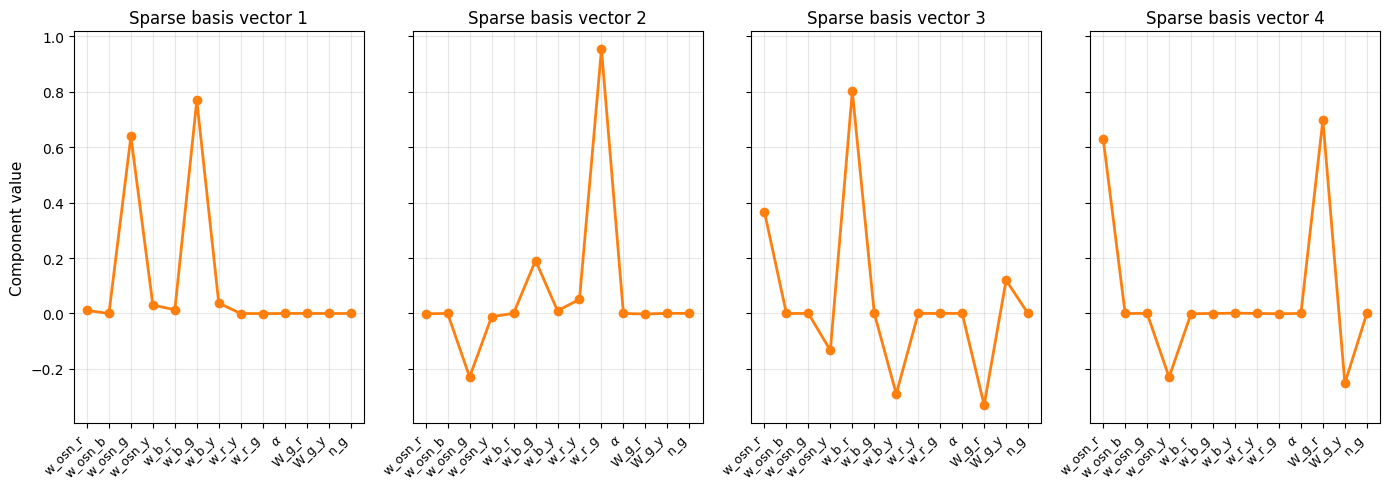

In [39]:
# Sparse basis from the first Q initialisation (keys[0] in the 1000-run batch)
U_sparse_first = U_sparse_save[1]  # same as sparse_rotation_vectorized(..., keys[:1])[0]
loss_first = float(loss_value_coll[0])

param_labels = [
    'w_osn_r', 'w_osn_b', 'w_osn_g', 'w_osn_y',
    'w_b_r', 'w_b_g', 'w_b_y',
    'w_r_y', 'w_r_g', r'$\alpha$', 'W_g_r', 'W_g_y',
    'n_g',
]

n_components = U_sparse_first.shape[1]
x_params = np.arange(U_sparse_first.shape[0])

fig, axes = plt.subplots(1, n_components, figsize=(3.5 * n_components, 5), sharex=True, sharey=True)
if n_components == 1:
    axes = [axes]

for col in range(n_components):
    axes[col].plot(x_params, U_sparse_first[:, col], 'o-', color='C1', lw=2, ms=6)
    axes[col].set_xticks(x_params)
    axes[col].set_xticklabels(param_labels, rotation=45, ha='right', fontsize=9)
    axes[col].grid(True, alpha=0.3)
    axes[col].set_title(f'Sparse basis vector {col + 1}', fontsize=12)
    if col == 0:
        axes[col].set_ylabel('Component value', fontsize=11)


plt.tight_layout()
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


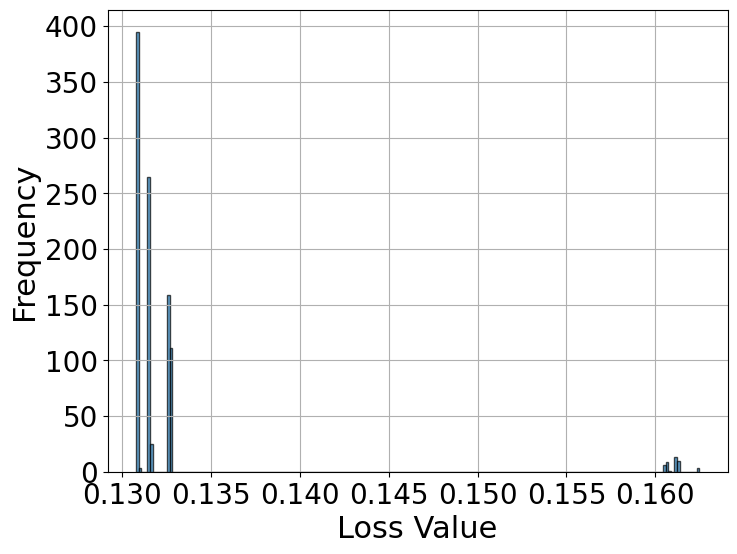

In [19]:
# plot histogram of loss values

plt.figure(figsize=(8,6))
plt.hist(loss_value_coll, bins=200, alpha=0.7, edgecolor='black')
plt.xlabel('Loss Value', fontsize=22)
plt.ylabel('Frequency', fontsize=22)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.grid()
plt.savefig('Figures_final/sparse_loss_histogram.eps')
plt.show()


In [45]:
# Isolate lowest-loss cluster and check subspace matching
# Split all 1000 solutions into 3 broad clusters

kmeans3 = KMeans(n_clusters=2, random_state=0, n_init=10)
labels3 = kmeans3.fit_predict(loss_value_coll.reshape(-1, 1))
centroids3 = kmeans3.cluster_centers_.flatten()
best_cluster_id = np.argmin(centroids3)

best_mask_broad = labels3 == best_cluster_id
loss_broad = loss_value_coll[best_mask_broad]

print(f"3-cluster centroids (sorted): {np.sort(centroids3)}")
print(f"Broad lowest cluster: {best_mask_broad.sum()} solutions, "
      f"loss ∈ [{loss_broad.min():.6f}, {loss_broad.max():.6f}]")


3-cluster centroids (sorted): [0.13154805 0.16107477]
Broad lowest cluster: 958 solutions, loss ∈ [0.130761, 0.132808]


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


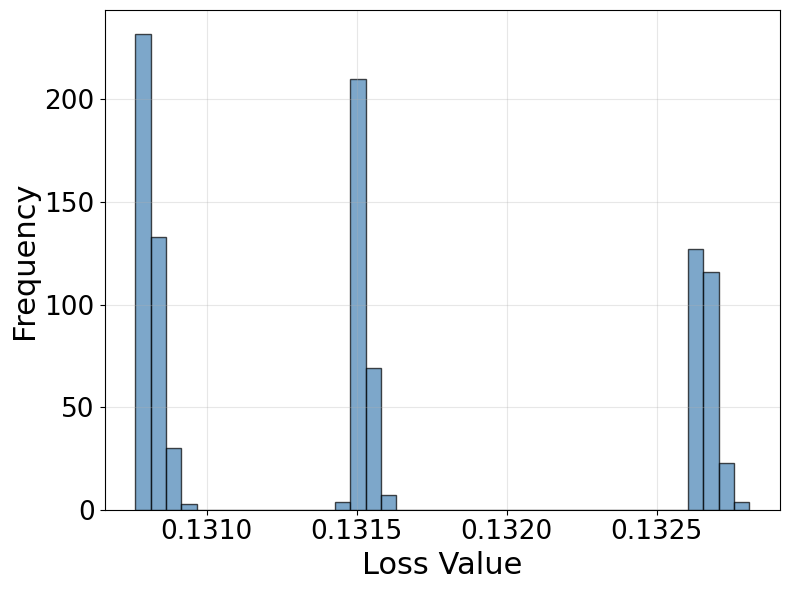

In [46]:
# Zoom into the lowest cluster (2 sub-peaks)
fig, ax = plt.subplots(figsize=(8, 6))

# Zoomed histogram of lowest broad cluster
ax.hist(loss_broad, bins=40, alpha=0.7, edgecolor='black', color='steelblue')
ax.set_xlabel('Loss Value', fontsize=22)
ax.set_ylabel('Frequency', fontsize=22)
ax.tick_params(axis='both', labelsize=19)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('Figures_final/sparse_loss_histogram_lowest_peak.eps')
plt.show()

In [47]:
U_sparse_save.shape

(1000, 13, 4)

In [48]:
# Use entire lowest broad cluster as U_best (no sub-clustering)
broad_indices = np.where(best_mask_broad)[0]
sub_best_indices = broad_indices  # global θ* indices (for downstream cells)

U_best = U_sparse_save[broad_indices]          # shape: (n_best, 12, 4)
loss_best = loss_value_coll[broad_indices]

print(f"\nLowest broad cluster: {U_best.shape[0]} solutions, "
      f"loss ∈ [{loss_best.min():.6f}, {loss_best.max():.6f}]")



Lowest broad cluster: 958 solutions, loss ∈ [0.130761, 0.132808]


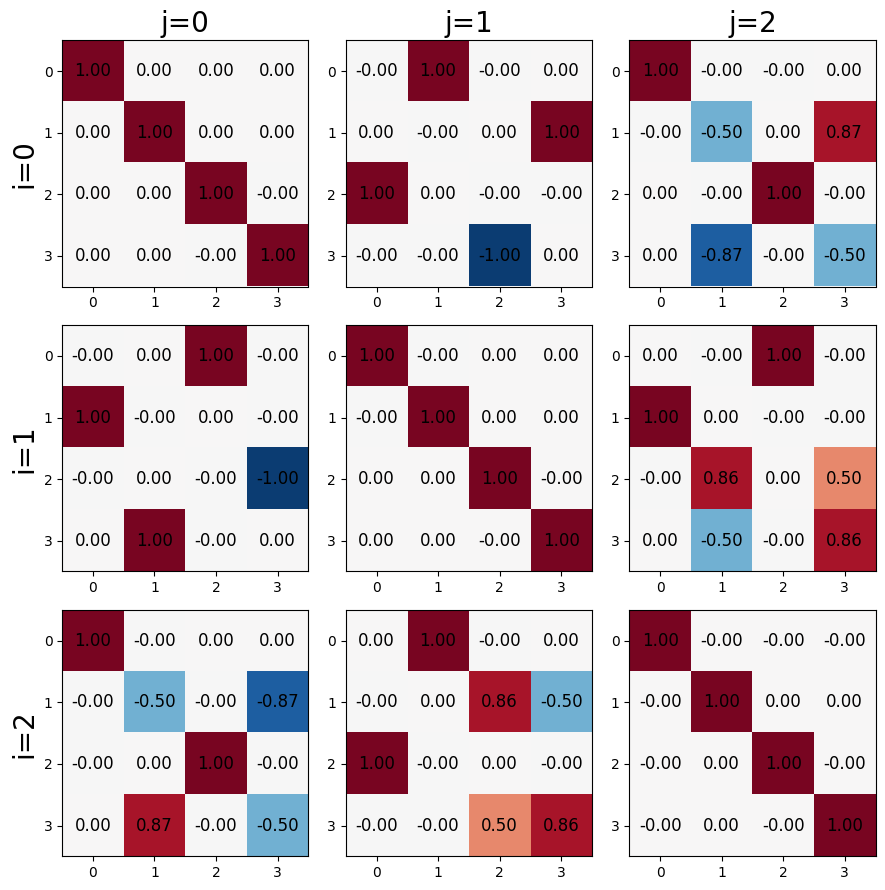

In [49]:
# Pairwise dot products  U_i^T @ U_j  for the lowest sub-peak
n_best = U_best.shape[0]
n_show = min(n_best, 3)

fig, axes_grid = plt.subplots(n_show, n_show, figsize=(3 * n_show, 3 * n_show))
for i in range(n_show):
    for j in range(n_show):
        P = U_best[i].T @ U_best[j]   # (4, 4)
        axes_grid[i, j].imshow(P, cmap='RdBu_r', vmin=-1.05, vmax=1.05)
        axes_grid[i, j].set_xticks(range(4))
        axes_grid[i, j].set_yticks(range(4))
        for ri in range(4):
            for ci in range(4):
                axes_grid[i, j].text(ci, ri, f'{P[ri, ci]:.2f}',
                                     ha='center', va='center', fontsize=12)
        if i == 0:
            axes_grid[i, j].set_title(f'j={j}', fontsize=20)
        if j == 0:
            axes_grid[i, j].set_ylabel(f'i={i}', fontsize=20)
plt.tight_layout()
plt.savefig('Figures_final/sparse_dot_products_3x3.eps')
plt.show()

In [50]:
# Quantitative signed-permutation check
max_off_perm = []
for i in range(n_best):
    for j in range(i + 1, n_best):
        P = U_best[i].T @ U_best[j]
        absP = np.abs(P)
        row_max = absP.max(axis=1)
        row_residual = absP.sum(axis=1) - row_max   # should be ~0
        max_off_perm.append(row_residual.max())

max_off_perm = np.array(max_off_perm)
print(f"\n── Signed permutation check ({n_best} solutions, "
      f"{len(max_off_perm)} pairs) ──")
print(f"Row residual (should be ~0):  mean={max_off_perm.mean():.4f},  "
      f"max={max_off_perm.max():.4f}")
#print(f"Pairs with residual < 0.10: {(max_off_perm < 0.10).mean():.1%}")
print(f"Pairs with residual < 0.05: {(max_off_perm < 0.05).mean():.1%}")
print(f"Pairs with residual < 0.01: {(max_off_perm < 0.01).mean():.1%}")


── Signed permutation check (958 solutions, 458403 pairs) ──
Row residual (should be ~0):  mean=0.3249,  max=0.5787
Pairs with residual < 0.05: 34.3%
Pairs with residual < 0.01: 34.2%


In [51]:
# Identify the two distinct sparse solutions and plot them

param_labels = [
    'w_osn_r', 'w_osn_b', 'w_osn_g', 'w_osn_y',
    'w_b_r', 'w_b_g', 'w_b_y',
    'w_r_y', 'w_r_g', '$\alpha$', 'W_g_r', 'W_g_y',
    'n_g',
]

# Split U_best into 2 groups 
# Use solution 0 as reference: compute row residual of U_0^T @ U_j for all j
ref = U_best[0]  # (12, 4)
residuals = np.zeros(U_best.shape[0])
for j in range(U_best.shape[0]):
    P = ref.T @ U_best[j]
    absP = np.abs(P)
    row_max = absP.max(axis=1)
    residuals[j] = (absP.sum(axis=1) - row_max).max()

threshold = 0.05
group_A_mask = residuals < threshold
group_B_mask = ~group_A_mask

n_A, n_B = group_A_mask.sum(), group_B_mask.sum()
print(f"Group A (same as ref): {n_A} solutions")
print(f"Group B (different):   {n_B} solutions")

Group A (same as ref): 398 solutions
Group B (different):   560 solutions


In [52]:
# Sub-split outer Group B (~group_A_mask): use first member as reference
# group_B_mask is redefined below as an inner mask over U_B
U_B = U_best[~group_A_mask]
loss_at_B = loss_best[~group_A_mask]
ref_B = U_B[0]  # (12, 4)
residuals_B = np.zeros(U_B.shape[0])
for j in range(U_B.shape[0]):
    P = ref_B.T @ U_B[j]
    absP = np.abs(P)
    row_max = absP.max(axis=1)
    residuals_B[j] = (absP.sum(axis=1) - row_max).max()

threshold = 0.05
group_B_mask = residuals_B < threshold  # inner mask, length U_B.shape[0]
group_C_mask = ~group_B_mask

n_B, n_C = group_B_mask.sum(), group_C_mask.sum()
print(f"Group B (same as ref_B): {n_B} solutions")
print(f"Group C (different):     {n_C} solutions")

Group B (same as ref_B): 270 solutions
Group C (different):     290 solutions


In [53]:
# Sub-split Group C rest: use first member as reference
# group_C_mask is redefined below as an inner mask over U_C
U_C = U_B[group_C_mask]
loss_at_C = loss_at_B[group_C_mask]
ref_C = U_C[0]  # (12, 4)
residuals_C = np.zeros(U_C.shape[0])
for j in range(U_C.shape[0]):
    P = ref_C.T @ U_C[j]
    absP = np.abs(P)
    row_max = absP.max(axis=1)
    residuals_C[j] = (absP.sum(axis=1) - row_max).max()

threshold = 0.05
group_C_mask = residuals_C < threshold  # inner mask, length U_C.shape[0]
group_D_mask = ~group_C_mask

n_C, n_D = group_C_mask.sum(), group_D_mask.sum()
print(f"Group C (same as ref_C): {n_C} solutions")
print(f"Group D (different):     {n_D} solutions")

Group C (same as ref_C): 290 solutions
Group D (different):     0 solutions


In [60]:
# Pick representative from each group (lowest loss within group)
loss_A = loss_best[group_A_mask]
loss_B = loss_at_B[group_B_mask]
loss_C = loss_at_C[group_C_mask]

rep_A = U_best[group_A_mask][np.argmin(loss_A)]
rep_B = U_B[group_B_mask][np.argmin(loss_B)]
rep_C = U_C[group_C_mask][np.argmin(loss_C)]


In [61]:
# Sort columns by sparsity 
def sort_by_sparsity(M):
    sums = np.abs(M).sum(0)
    order = np.argsort(sums)[::-1]
    return M[:, order], order

rep_A_sorted, order_A = sort_by_sparsity(rep_A)
rep_B_sorted, order_B = sort_by_sparsity(rep_B)
rep_C_sorted, order_C = sort_by_sparsity(rep_C)


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


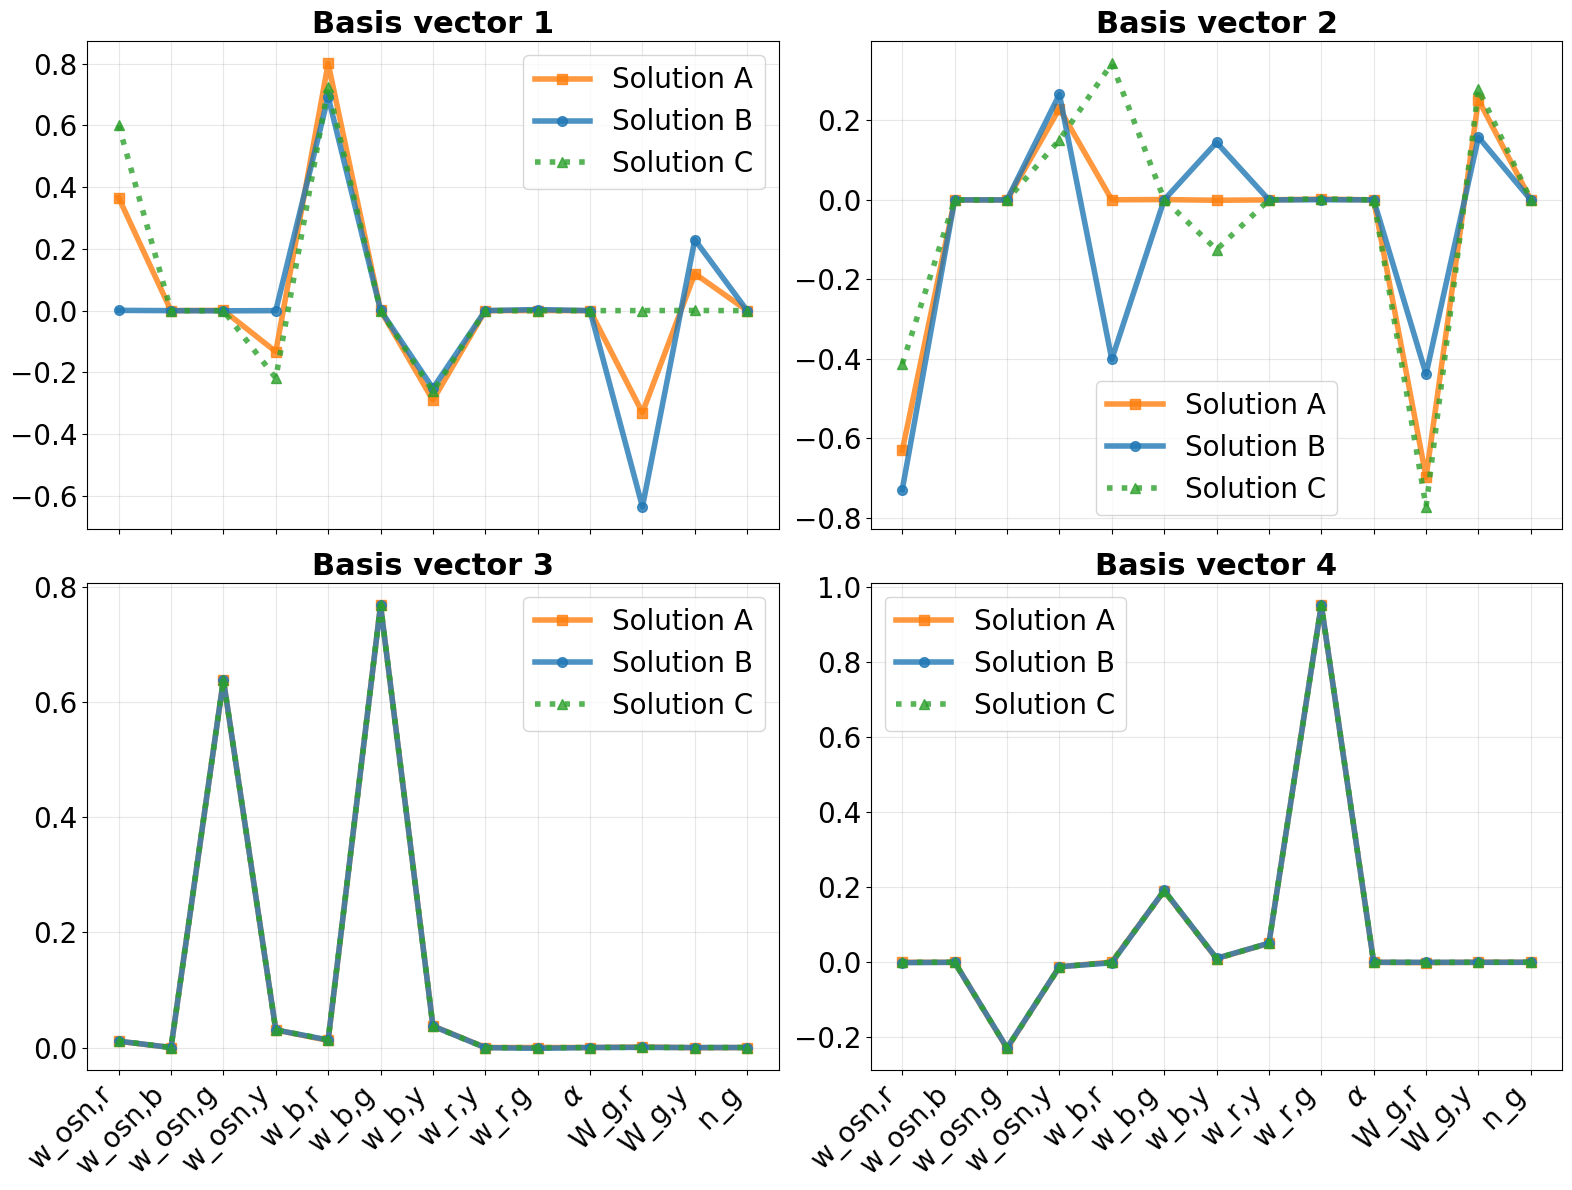


Sparsity pattern (entries with |value| > 0.1)

Solution A:
  Basis vector 1: [('w_osn_r', '0.366'), ('w_osn_y', '-0.133'), ('w_b_r', '0.801'), ('w_b_y', '-0.290'), ('W_g_r', '-0.330'), ('W_g_y', '0.120')]
  Basis vector 2: [('w_osn_r', '-0.630'), ('w_osn_y', '0.230'), ('W_g_r', '-0.698'), ('W_g_y', '0.252')]
  Basis vector 3: [('w_osn_g', '0.638'), ('w_b_g', '0.768')]
  Basis vector 4: [('w_osn_g', '-0.229'), ('w_b_g', '0.191'), ('w_r_g', '0.953')]

Solution B:
  Basis vector 1: [('w_b_r', '0.693'), ('w_b_y', '-0.252'), ('W_g_r', '-0.635'), ('W_g_y', '0.230')]
  Basis vector 2: [('w_osn_r', '-0.729'), ('w_osn_y', '0.265'), ('w_b_r', '-0.401'), ('w_b_y', '0.144'), ('W_g_r', '-0.438'), ('W_g_y', '0.158')]
  Basis vector 3: [('w_osn_g', '0.638'), ('w_b_g', '0.768')]
  Basis vector 4: [('w_osn_g', '-0.228'), ('w_b_g', '0.192'), ('w_r_g', '0.953')]

Solution C:
  Basis vector 1: [('w_osn_r', '0.600'), ('w_osn_y', '-0.218'), ('w_b_r', '0.723'), ('w_b_y', '-0.262')]
  Basis vector 2: [('w_os

In [62]:
# Align B, C to A (optimal permutation + sign flips)
def align_to_reference(ref_sorted, M_sorted):
    P = ref_sorted.T @ M_sorted
    row_ind, col_ind = linear_sum_assignment(-np.abs(P))
    M_aligned = M_sorted[:, col_ind]
    signs = np.sign(np.array([P[r, c] for r, c in zip(row_ind, col_ind)]))
    return M_aligned * signs[None, :]

rep_B_aligned = align_to_reference(rep_A_sorted, rep_B_sorted)
rep_C_aligned = align_to_reference(rep_A_sorted, rep_C_sorted)

# Overlay – aligned comparison (A, B, C)
# 12 theta parameters + learnable n_g (matches unpack_theta / rep_A_sorted rows)
param_labels = [
    'w_osn_r', 'w_osn_b', 'w_osn_g', 'w_osn_y',
    'w_b_r', 'w_b_g', 'w_b_y',
    'w_r_y', 'w_r_g', r'$\alpha$', 'W_g_r', 'W_g_y',
    'n_g',
]
x_labels = []
for lbl in param_labels:
    if lbl.count('_') >= 2:
        base, suffix = lbl.rsplit('_', 1)
        x_labels.append(f'{base},{suffix}')
    else:
        x_labels.append(lbl)
x_params = np.arange(rep_A_sorted.shape[0])

fig, axes2 = plt.subplots(2, 2, figsize=(16, 12))
axes2 = axes2.flatten()
styles = [
    ('Solution A', rep_A_sorted, 's-', 'tab:orange'),
    ('Solution B', rep_B_aligned, 'o-', 'tab:blue'),
    ('Solution C', rep_C_aligned, '^:', 'tab:green'),
]

for i in range(4):
    for label, M, fmt, color in styles:
        axes2[i].plot(x_params, M[:, i], fmt, color=color, lw=4, ms=7, label=label, alpha=0.8)
    axes2[i].set_xticks(x_params)
    if i >= 2:
        axes2[i].set_xticklabels(x_labels, rotation=45, ha='right', fontsize=20)
    else:
        axes2[i].tick_params(labelbottom=False)
    axes2[i].tick_params(axis='y', labelsize=20)
    axes2[i].grid(True, alpha=0.3)
    axes2[i].set_title(f'Basis vector {i+1}', fontsize=22, fontweight='bold')
    axes2[i].legend(fontsize=20)

plt.tight_layout()
plt.savefig('Figures_final/ng_rep_A_B_C_overlay.eps')
plt.show()

# Print sparsity patterns
print("\nSparsity pattern (entries with |value| > 0.1)")
for label, M_sorted in [
    ("Solution A", rep_A_sorted),
    ("Solution B", rep_B_aligned),
    ("Solution C", rep_C_aligned),
]:
    print(f"\n{label}:")
    for col in range(4):
        nonzero_params = [(param_labels[row], f"{M_sorted[row, col]:.3f}")
                          for row in range(len(param_labels)) if abs(M_sorted[row, col]) > 0.1]
        print(f"  Basis vector {col+1}: {nonzero_params}")